# Homework 6 
## Yuxin Yang 1505451394

In [1]:
from pathlib import Path
import io
import zipfile
import urllib.request
import time
import platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                             RocCurveDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, average_precision_score)
from sklearn.svm import SVC
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier

SEED = 552
N_JOBS = 4
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_rows', 180)
pd.set_option('display.max_columns', 15)
print('Python:', platform.python_version())
for package in ['numpy', 'pandas', 'scikit-learn', 'imbalanced-learn', 'xgboost']:
    print(f'{package}: {metadata.version(package)}')

Python: 3.13.5
numpy: 2.3.4
pandas: 2.3.3
scikit-learn: 1.9.1
imbalanced-learn: 0.14.2
xgboost: 2.1.4


## 1(a). Load and check the APS data

The official split is useful here because I can evaluate every model on the same held-out trucks. The CSVs contain a preamble, so I locate the actual header rather than guessing how many lines to skip.

In [2]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)
filenames = ['aps_failure_training_set.csv', 'aps_failure_test_set.csv']
if not all((DATA / name).exists() for name in filenames):
    url = 'https://archive.ics.uci.edu/static/public/421/aps+failure+at+scania+trucks.zip'
    with urllib.request.urlopen(url) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    for name in filenames:
        matches = [member for member in archive.namelist() if Path(member).name == name]
        if len(matches) != 1:
            raise ValueError(f'Cannot uniquely locate {name} in archive')
        (DATA / name).write_bytes(archive.read(matches[0]))

def read_aps(path):
    with path.open() as f:
        header = next(i for i, line in enumerate(f) if line.startswith('class,'))
    return pd.read_csv(path, skiprows=header, na_values='na')

train = read_aps(DATA / filenames[0])
test = read_aps(DATA / filenames[1])
X_train = train.drop(columns='class')
X_test = test.drop(columns='class')
y_train = train['class'].map({'neg': 0, 'pos': 1})
y_test = test['class'].map({'neg': 0, 'pos': 1})
assert train.shape == (60000, 171) and test.shape == (16000, 171)
assert X_train.columns.equals(X_test.columns)
assert not y_train.isna().any() and not y_test.isna().any()
print('Training shape:', train.shape, '| Test shape:', test.shape)
display(train.head())

Training shape: (60000, 171) | Test shape: (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,...,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,...,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,...,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,...,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,...,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,...,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


## 1(b)(i). Missing values

Common options include deleting incomplete observations, filling with a mean/median/mode or a constant, K-nearest-neighbor imputation, and multivariate iterative imputation. Multiple imputation can also represent uncertainty by creating several completed datasets rather than treating one fill-in as certain. Deletion can lose too much information; mean imputation is sensitive to outliers; KNN and iterative methods are more expensive and introduce additional modeling choices.

I choose **median imputation** as a simple baseline because sensor values can be very skewed. It preserves every row and all 170 feature.

I fit medians on the training set and apply those same medians to the test set. Within CV, the medians are re-estimated on each training fold. The assignment's footnote suggests using test statistics; I instead use the usual deployment procedure, where a fitted preprocessing rule is applied to incoming observations without estimating new statistics from the evaluation batch.

In [3]:
missing = pd.DataFrame({
    'missing_train': X_train.isna().sum(),
    'missing_percent_train': 100 * X_train.isna().mean()
}).sort_values('missing_percent_train', ascending=False)
print(f'Missing training cells: {X_train.isna().to_numpy().mean():.2%}')
print(f'Training rows with at least one missing value: {X_train.isna().any(axis=1).sum():,}')
display(missing.head(15))
assert not X_train.isna().all().any(), 'An entirely missing feature needs an explicit fallback.'
eda_imputer = SimpleImputer(strategy='median')
X_eda = pd.DataFrame(eda_imputer.fit_transform(X_train), columns=X_train.columns)
assert X_eda.shape == (60000, 170) and not X_eda.isna().any().any()

Missing training cells: 8.33%
Training rows with at least one missing value: 59,409


,missing_train,missing_percent_train
br_000,49264,82.106667
bq_000,48722,81.203333
bp_000,47740,79.566667
bo_000,46333,77.221667
cr_000,46329,77.215000
ab_000,46329,77.215000
bn_000,44009,73.348333
bm_000,39549,65.915000
bl_000,27277,45.461667
bk_000,23034,38.390000


## 1(b)(ii). Coefficient of variation

I calculate $CV_j=s_j/m_j$ using the sample standard deviation (`ddof=1`) of the median-imputed training features. This makes the calculation consistent with the features passed to the models. For comparison, I also include CV based only on each column's observed entries. A zero mean makes CV undefined, so I record it as missing instead of dividing by zero. All 170 CV values are shown and saved. A high CV means a large spread relative to the mean; it does not establish predictive usefulness.

In [4]:
cv_table = pd.DataFrame({
    'mean_imputed': X_eda.mean(),
    'sample_std_imputed': X_eda.std(ddof=1),
    'CV': X_eda.std(ddof=1) / X_eda.mean().replace(0, np.nan),
    'CV_observed_only': X_train.std(ddof=1) / X_train.mean().replace(0, np.nan)
}).sort_values('CV', ascending=False)
cv_table.index.name = 'feature'
display(cv_table)
cv_table.to_csv('coefficient_of_variation.csv')

,mean_imputed,sample_std_imputed,CV,CV_observed_only
feature,,,,
cf_000,1.431075e+05,3.504525e+07,244.887517,212.406837
co_000,1.433300e+05,3.504525e+07,244.507385,212.079320
ad_000,1.434383e+05,3.504525e+07,244.322816,211.962417
cs_009,7.705097e+02,1.833278e+05,237.930554,236.600371
dh_000,4.392641e+03,5.412441e+05,123.216097,119.029346
dj_000,3.727133e+01,4.379166e+03,117.494225,113.502884
ag_000,2.191577e+02,2.036364e+04,92.917755,92.396677
as_000,1.254079e+02,1.095219e+04,87.332500,86.873473
ay_009,1.149620e+03,9.741156e+04,84.733735,84.258541


## 1(b)(iii). Feature correlation matrix

I use Pearson correlation on the imputed training data. The blocks indicate groups of sensors that move together.

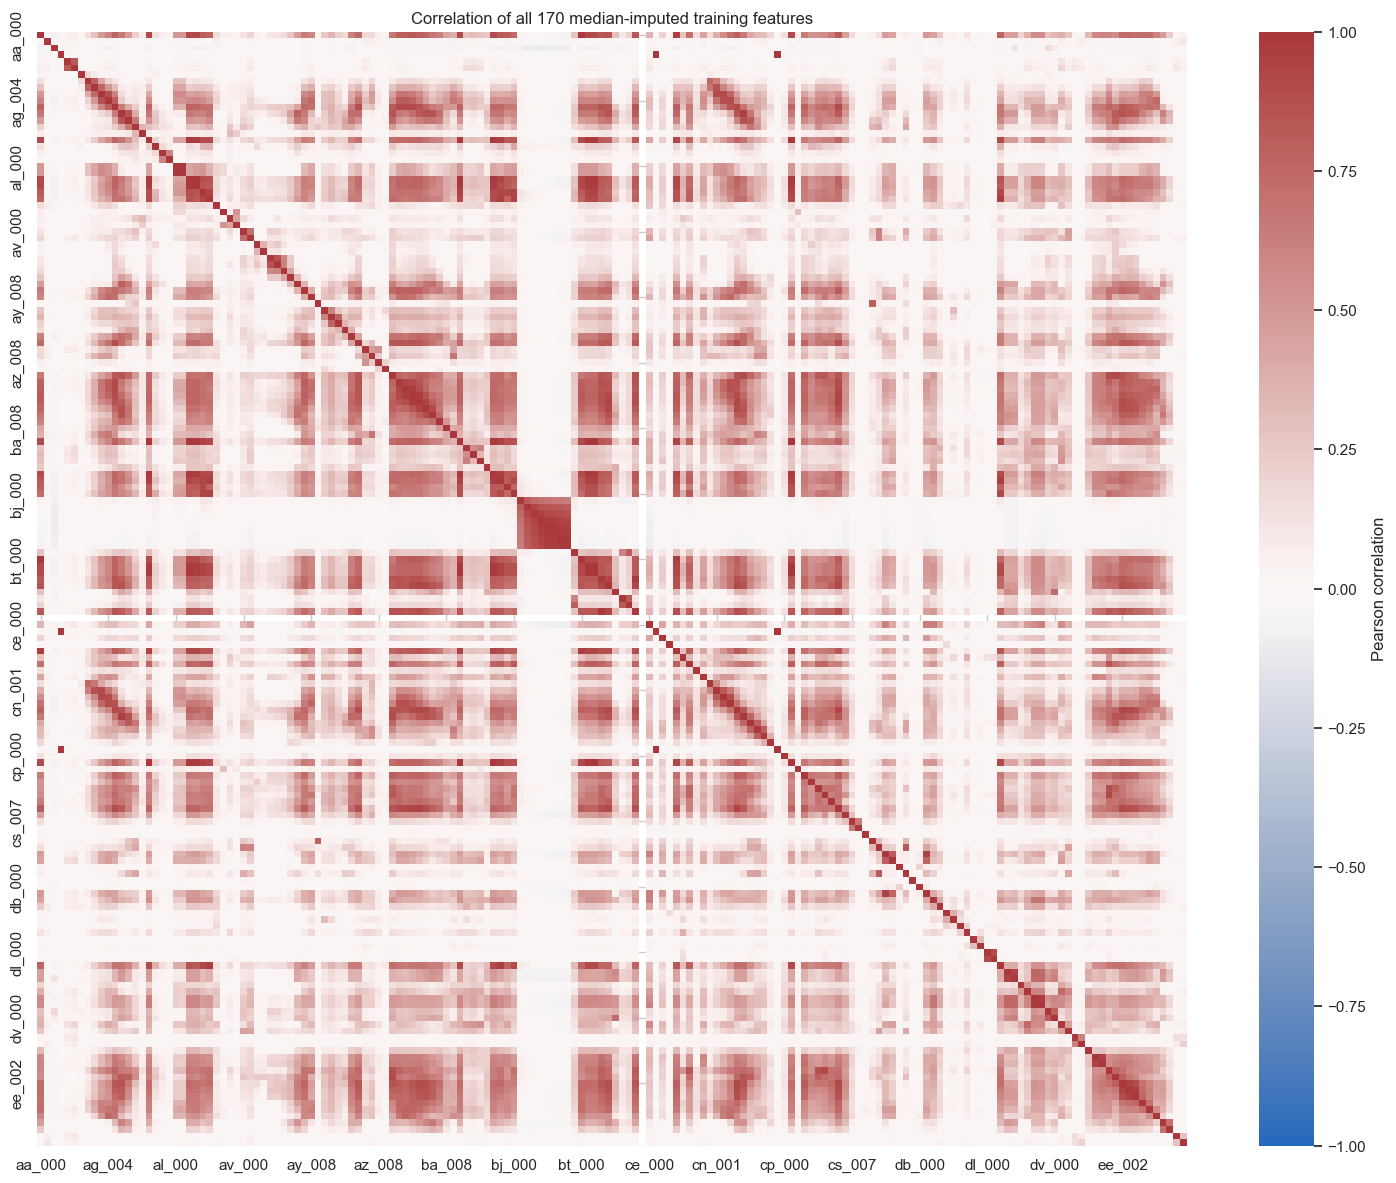

In [5]:
corr = X_eda.corr()
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr, cmap='vlag', center=0, vmin=-1, vmax=1,
            xticklabels=10, yticklabels=10, ax=ax,
            cbar_kws={'label': 'Pearson correlation'})
ax.set_title('Correlation of all 170 median-imputed training features')
plt.tight_layout()
plt.show()

## 1(b)(iv). Visualize the 13 highest-CV features

$\lfloor\sqrt{170}\rfloor=13$. I use a scatterplot matrix, with class colors, and a separate box plot for each feature. To make rare failures visible without drawing millions of overlapping points, the scatter matrix uses up to 500 observations per class, sampled reproducibly. This balanced plotting sample is **only** for the figure; the models use all 60,000 training rows. Box plots use the full training data. I use $\log(1+x)$ axes in these figures because the raw distributions have long tails; CV itself was calculated on the original scale.

Highest-CV features: cf_000, co_000, ad_000, cs_009, dh_000, dj_000, ag_000, as_000, ay_009, ak_000, az_009, ch_000, au_000


,mean_imputed,sample_std_imputed,CV,CV_observed_only
feature,,,,
cf_000,143107.534133,3.504525e+07,244.887517,212.406837
co_000,143330.017733,3.504525e+07,244.507385,212.079320
ad_000,143438.292067,3.504525e+07,244.322816,211.962417
cs_009,770.509700,1.833278e+05,237.930554,236.600371
dh_000,4392.640833,5.412441e+05,123.216097,119.029346
dj_000,37.271333,4.379166e+03,117.494225,113.502884
ag_000,219.157733,2.036364e+04,92.917755,92.396677
as_000,125.407900,1.095219e+04,87.332500,86.873473
ay_009,1149.619633,9.741156e+04,84.733735,84.258541


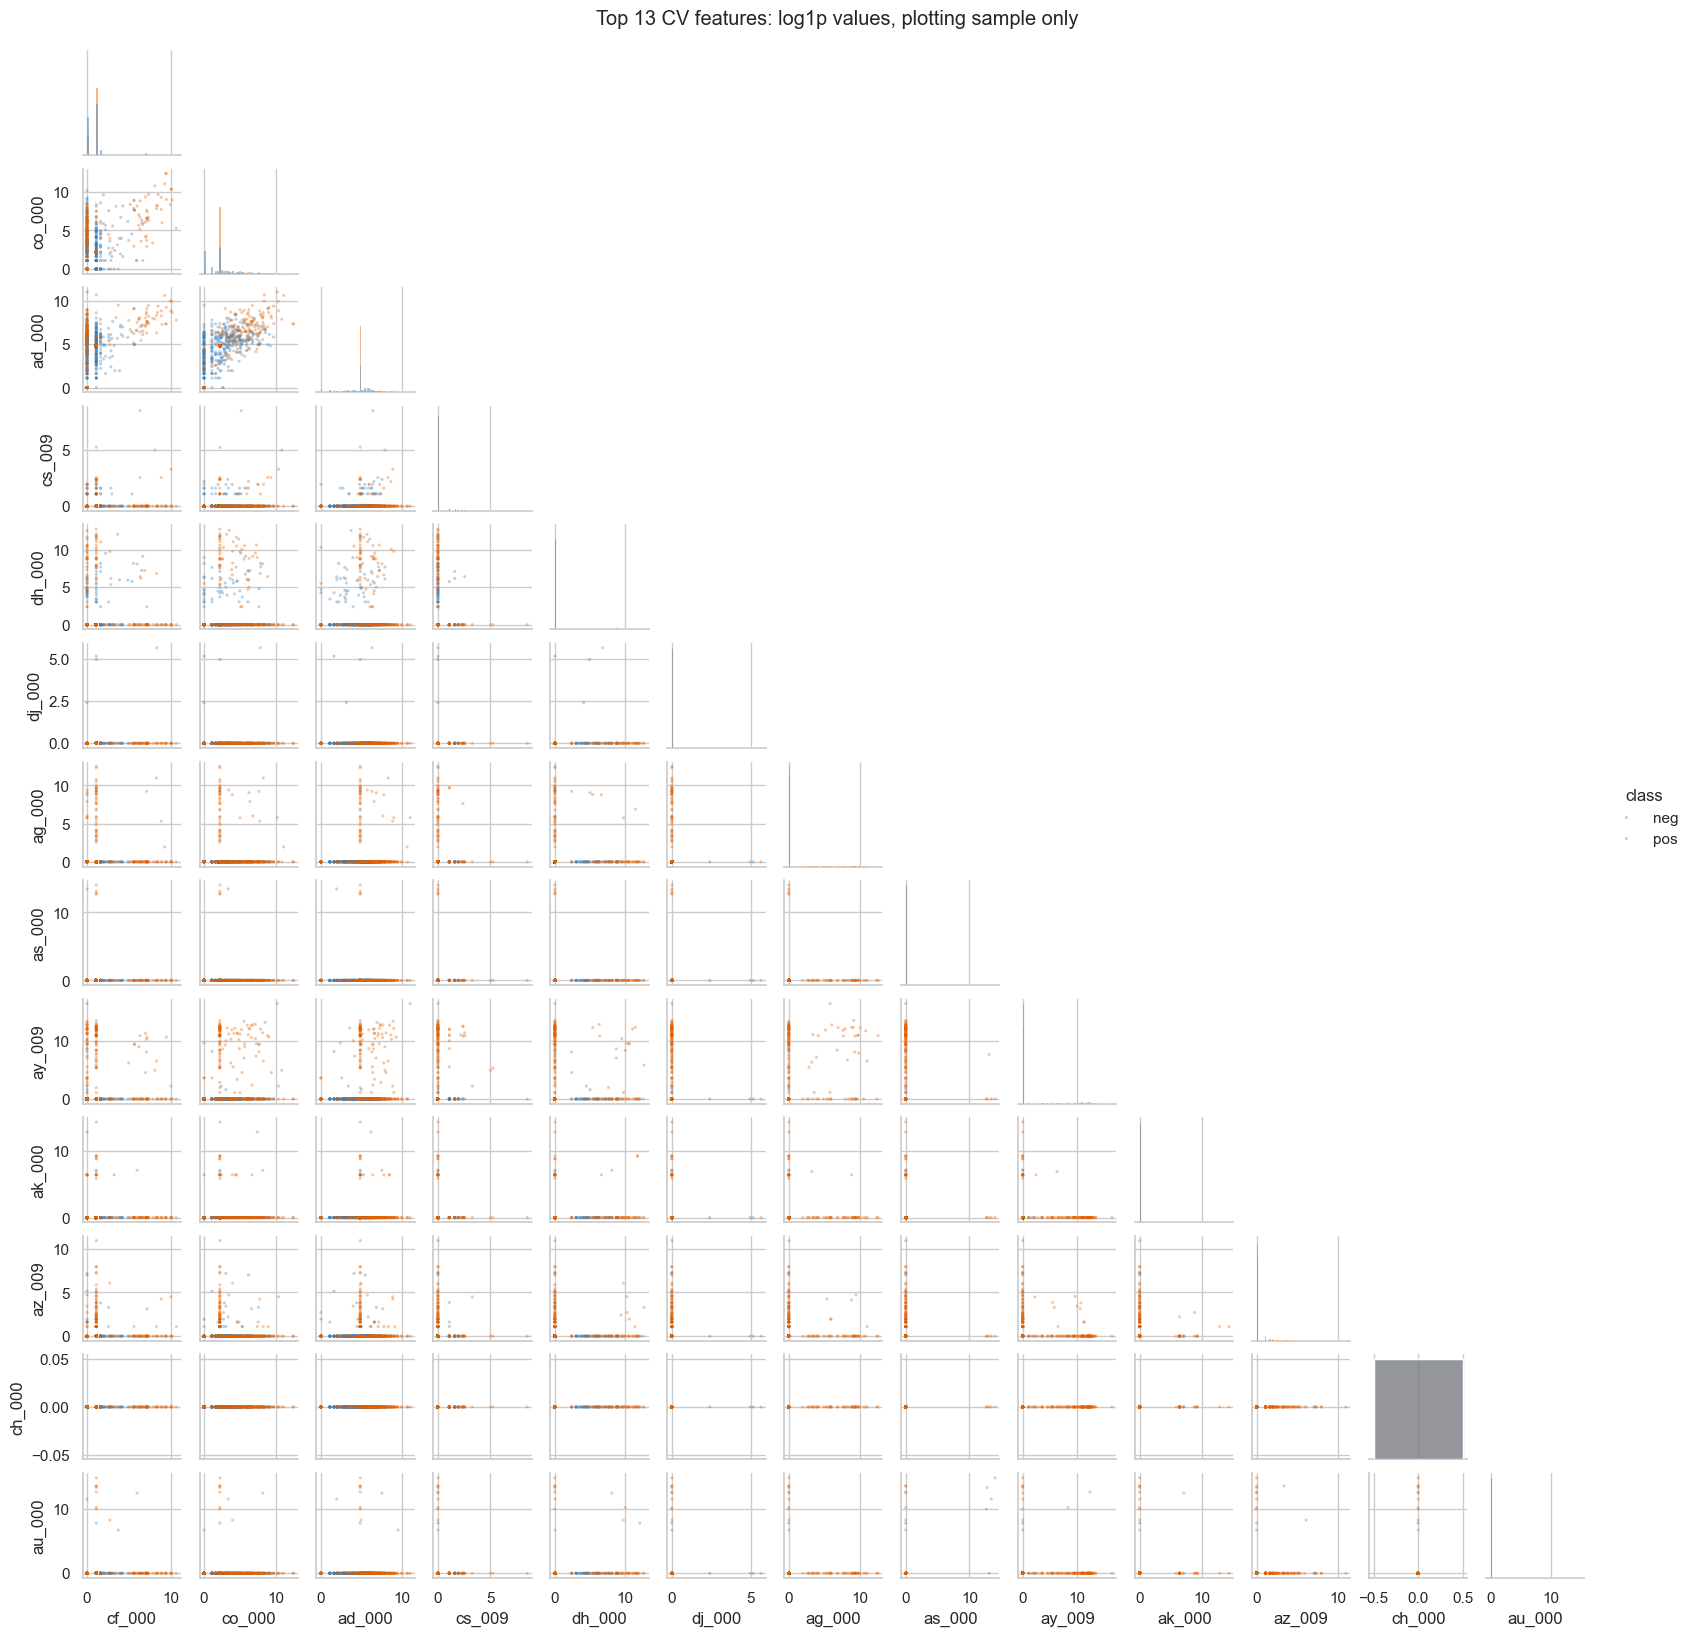

In [6]:
top_features = cv_table['CV'].dropna().head(int(np.sqrt(170))).index.tolist()
print('Highest-CV features:', ', '.join(top_features))
display(cv_table.loc[top_features])
assert (X_eda[top_features] >= 0).all().all()
plot_frame = np.log1p(X_eda[top_features]).copy()
plot_frame['class'] = y_train.map({0: 'neg', 1: 'pos'}).to_numpy()
plot_sample = pd.concat([
    group.sample(n=min(500, len(group)), random_state=SEED)
    for _, group in plot_frame.groupby('class')
])
g = sns.pairplot(plot_sample, vars=top_features, hue='class',
                 hue_order=['neg', 'pos'], palette={'neg': '#377eb8', 'pos': '#e66101'},
                 diag_kind='hist', corner=True, height=1.25,
                 plot_kws={'s': 5, 'alpha': 0.35, 'linewidth': 0})
g.fig.suptitle('Top 13 CV features: log1p values, plotting sample only', y=1.01)
g.savefig('top_cv_scatter_matrix.png', dpi=160, bbox_inches='tight')
plt.show()

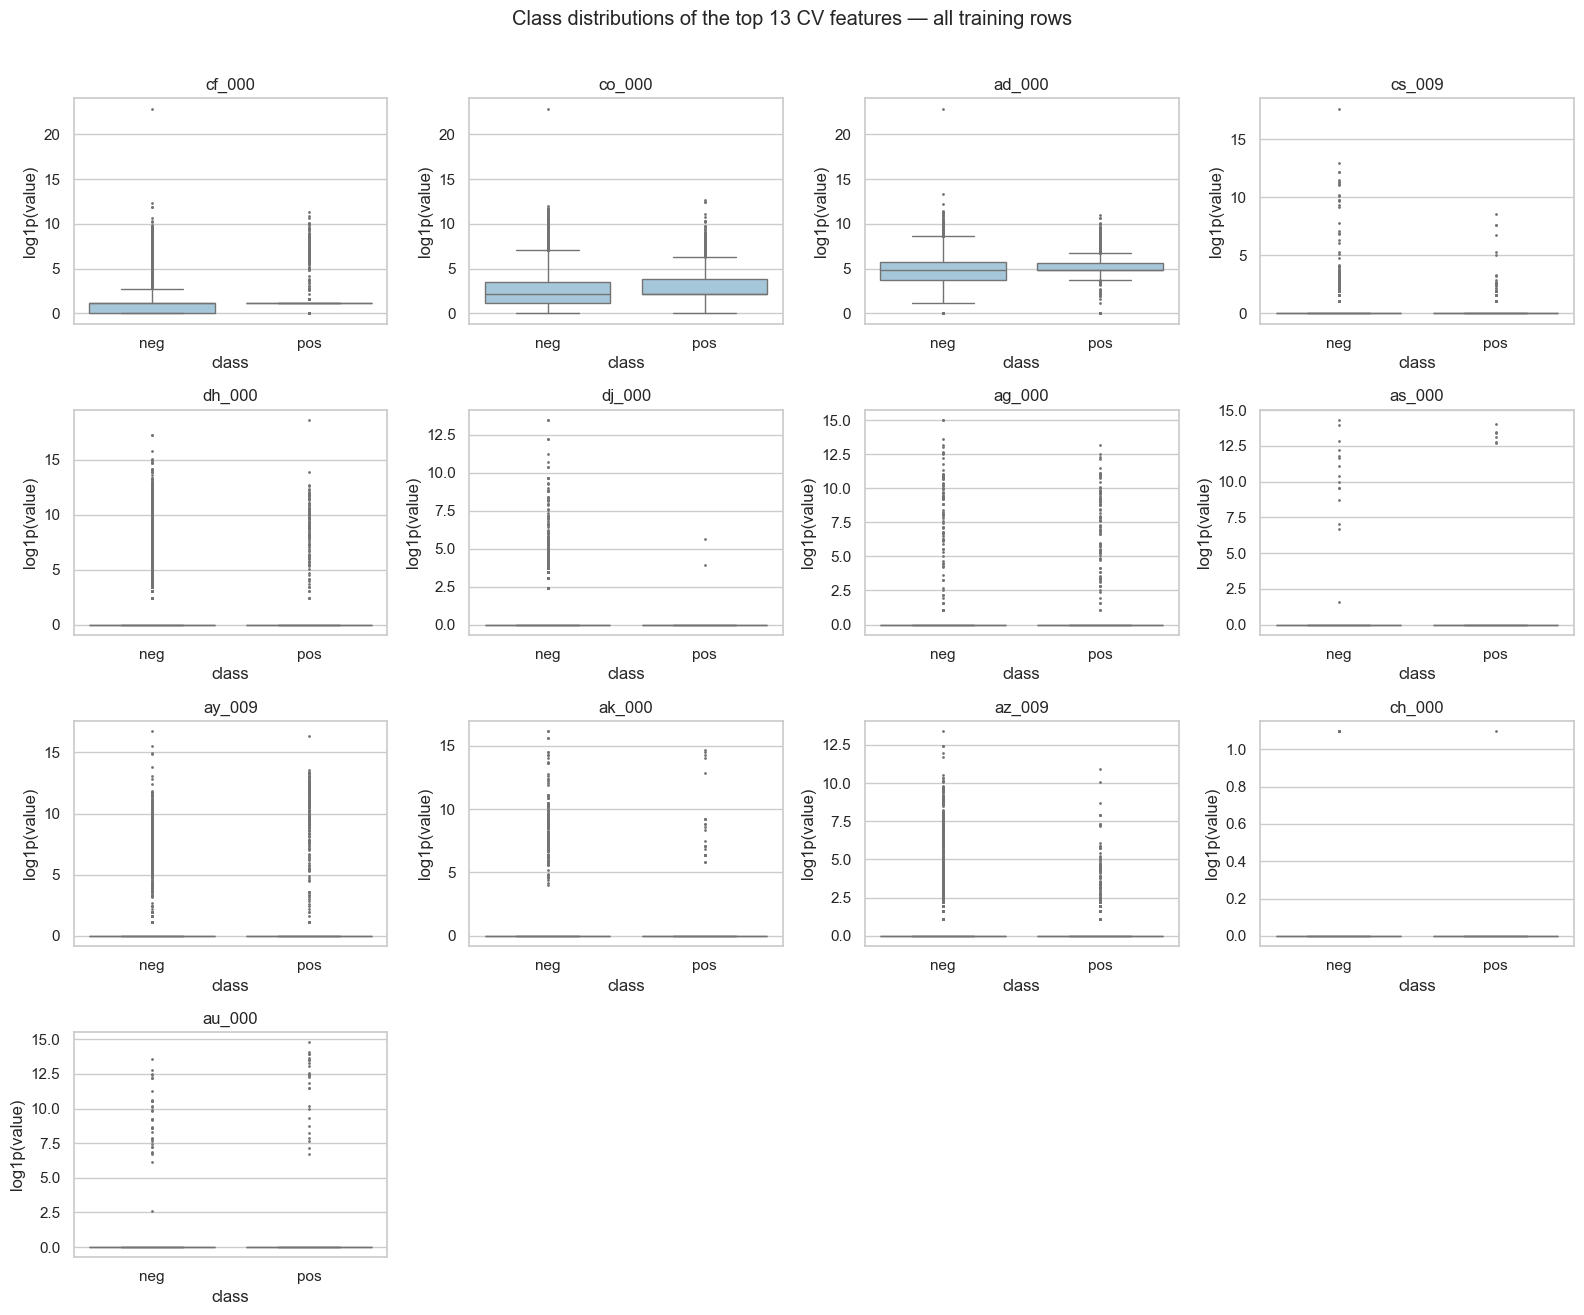

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, feature in zip(axes.flat, top_features):
    sns.boxplot(data=plot_frame, x='class', y=feature,
                order=['neg', 'pos'], color='#9ecae1', fliersize=1, ax=ax)
    ax.set_title(feature)
    ax.set_ylabel('log1p(value)')
for ax in axes.flat[len(top_features):]:
    ax.set_visible(False)
fig.suptitle('Class distributions of the top 13 CV features — all training rows', y=1.01)
plt.tight_layout()
plt.show()

The plots show considerable overlap between the two classes. We cannot determine feature significance from scatter plots alone, and a high CV does not necessarily indicate predictive importance. The 13 features were selected only for visualization; all 170 features are used in the models.

## 1(b)(v). Class balance

In [8]:
class_counts = pd.DataFrame({
    'training': y_train.value_counts().reindex([0, 1]),
    'test': y_test.value_counts().reindex([0, 1])
}).rename(index={0: 'neg', 1: 'pos'})
display(class_counts)
print(f'Training negative:positive ratio = {(y_train == 0).sum() / (y_train == 1).sum():.0f}:1')
print(f'Always-negative training error = {y_train.mean():.4%}')
print(f'Always-negative test error = {y_test.mean():.4%}')

,training,test
class,,
neg,59000,15625
pos,1000,375


Training negative:positive ratio = 59:1
Always-negative training error = 1.6667%
Always-negative test error = 2.3438%


The training set contains 59,000 negative and 1,000 positive observations, giving a 59:1 ratio. Therefore, the dataset is strongly imbalanced. A classifier that always predicts negative would achieve 98.33% training accuracy but miss every positive case.

In [9]:
results = []
fitted_models = {}

def evaluate_model(name, model):
    fitted_models[name] = model
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    for row, (split, X, y) in enumerate([
        ('train', X_train, y_train), ('test', X_test, y_test)
    ]):
        probability = model.predict_proba(X)[:, 1]
        prediction = (probability >= 0.5).astype(int)
        cm = confusion_matrix(y, prediction, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        results.append(dict(model=name, split=split,
                            error=1-accuracy_score(y, prediction),
                            ROC_AUC=roc_auc_score(y, probability),
                            AP=average_precision_score(y, probability),
                            precision=precision_score(y, prediction, zero_division=0),
                            recall=recall_score(y, prediction),
                            F1=f1_score(y, prediction), TN=tn, FP=fp, FN=fn, TP=tp))
        ConfusionMatrixDisplay(cm, display_labels=['neg', 'pos']).plot(
            ax=axes[row, 0], colorbar=False, cmap='Blues', values_format='d')
        axes[row, 0].set_title(f'{name} — {split}')
        RocCurveDisplay.from_predictions(y, probability, ax=axes[row, 1], name=split)
        axes[row, 1].plot([0, 1], [0, 1], 'k--', alpha=0.4)
        axes[row, 1].set_title(f'{split}: ROC curve')
    plt.tight_layout()
    plt.show()
    display(pd.DataFrame(results).query('model == @name').set_index('split').round(5))

## 1(c). Random forest without imbalance compensation

I use 200 trees, bootstrap sampling, and the square root of the number of predictors at each split. I leave the trees unpruned and do not use class weights or resampling. These settings are fixed in advance so the comparison in part (d) changes only the imbalance treatment.

Fit time: 19.5 seconds


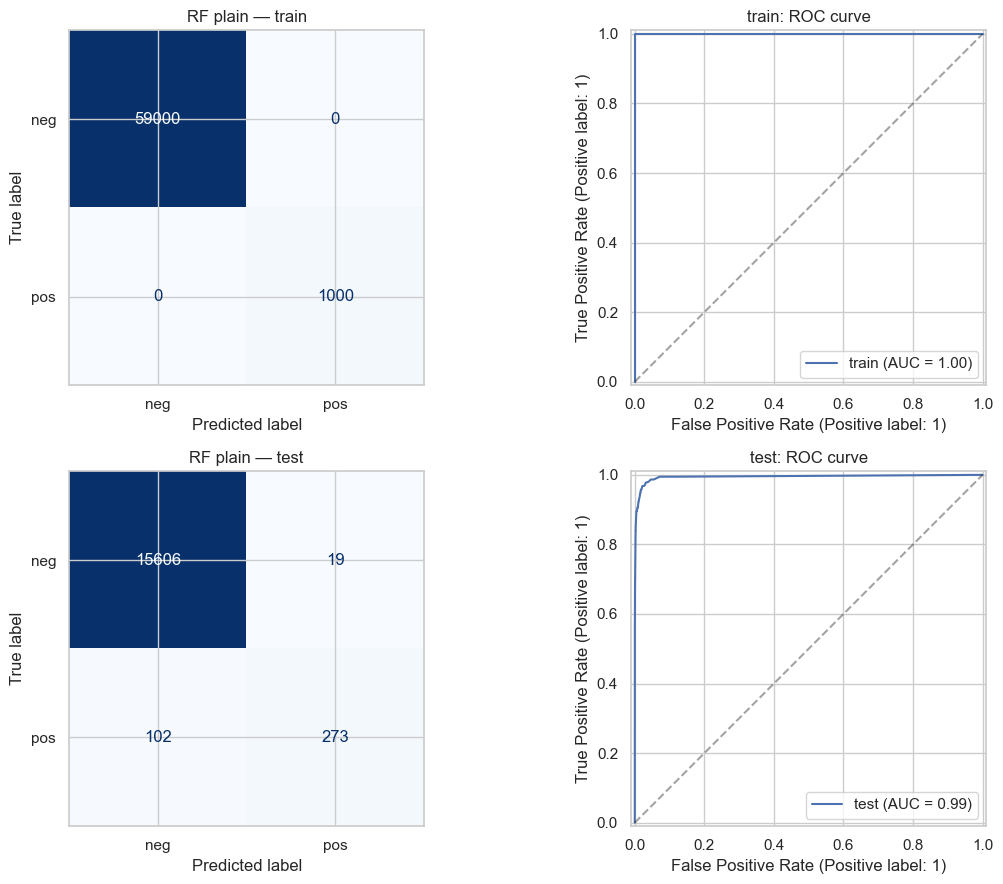

,model,error,ROC_AUC,AP,precision,recall,F1,TN,FP,FN,TP
split,,,,,,,,,,,
train,RF plain,0.00000,1.00000,1.00000,1.00000,1.000,1.00000,59000,0,0,1000
test,RF plain,0.00756,0.99439,0.92428,0.93493,0.728,0.81859,15606,19,102,273


In [10]:
rf_plain = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('rf', RandomForestClassifier(n_estimators=200, max_features='sqrt',
                                  bootstrap=True, oob_score=True,
                                  class_weight=None, random_state=SEED, n_jobs=N_JOBS))
])
start = time.perf_counter()
rf_plain.fit(X_train, y_train)
print(f'Fit time: {time.perf_counter()-start:.1f} seconds')
evaluate_model('RF plain', rf_plain)

In [11]:
oob_plain = 1 - rf_plain.named_steps['rf'].oob_score_
plain_test_error = next(r['error'] for r in results if r['model']=='RF plain' and r['split']=='test')
display(pd.DataFrame({'OOB error': [oob_plain], 'test error': [plain_test_error],
                      'test minus OOB': [plain_test_error-oob_plain]}, index=['RF plain']))

,OOB error,test error,test minus OOB
RF plain,0.0058,0.007563,0.001763


The OOB error is 0.58%, while the test error is approximately 0.76%. The test error is about 0.18 percentage points higher, so the OOB estimate is slightly optimistic in this experiment.

## 1(d). Random forest with imbalance compensation

Common approaches include weighting the minority class more heavily, undersampling the majority class, oversampling the minority class, and balanced bootstrap sampling. Threshold adjustment is another way to trade false positives against false negatives, but it needs validation data.

I use `class_weight='balanced_subsample'`, which recalculates inverse-frequency class weights in each bootstrap sample. It changes the split objective without discarding the majority-class rows.

Fit time: 11.9 seconds


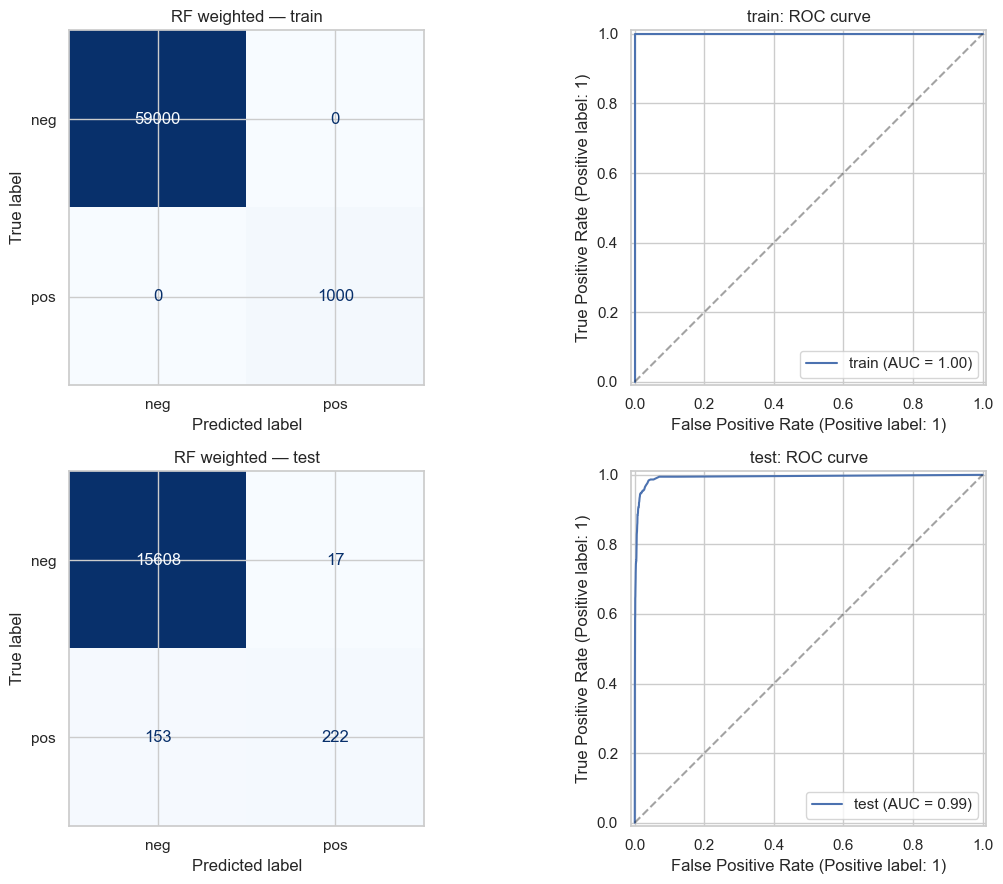

,model,error,ROC_AUC,AP,precision,recall,F1,TN,FP,FN,TP
split,,,,,,,,,,,
train,RF weighted,0.00000,1.00000,1.00000,1.00000,1.000,1.00000,59000,0,0,1000
test,RF weighted,0.01062,0.99331,0.88284,0.92887,0.592,0.72313,15608,17,153,222


error  ROC_AUC       AP  precision  recall       F1  \
model       split                                                          
RF plain    train  0.00000  1.00000  1.00000    1.00000   1.000  1.00000   
            test   0.00756  0.99439  0.92428    0.93493   0.728  0.81859   
RF weighted train  0.00000  1.00000  1.00000    1.00000   1.000  1.00000   
            test   0.01062  0.99331  0.88284    0.92887   0.592  0.72313   

                      TN  FP   FN    TP  
model       split                        
RF plain    train  59000   0    0  1000  
            test   15606  19  102   273  
RF weighted train  59000   0    0  1000  
            test   15608  17  153   222

,OOB error,test error
RF plain,0.005800,0.007563
RF weighted,0.007667,0.010625


In [12]:
rf_weighted = clone(rf_plain).set_params(rf__class_weight='balanced_subsample')
start = time.perf_counter()
rf_weighted.fit(X_train, y_train)
print(f'Fit time: {time.perf_counter()-start:.1f} seconds')
evaluate_model('RF weighted', rf_weighted)
oob_weighted = 1 - rf_weighted.named_steps['rf'].oob_score_
rf_comparison = pd.DataFrame(results).query("model.str.startswith('RF')", engine='python')
display(rf_comparison.set_index(['model', 'split']).round(5))
display(pd.DataFrame({
    'OOB error': [oob_plain, oob_weighted],
    'test error': [plain_test_error, rf_comparison.query("model=='RF weighted' and split=='test'")['error'].iloc[0]]
}, index=['RF plain', 'RF weighted']))

In [13]:
rf_test = rf_comparison.query("split == 'test'").set_index('model')

display(
    rf_test.loc[
        ['RF plain', 'RF weighted'],
        ['error', 'recall', 'ROC_AUC', 'FN', 'FP']
    ].style.format({
        'error': '{:.3%}',
        'recall': '{:.1%}',
        'ROC_AUC': '{:.4f}',
        'FN': '{:.0f}',
        'FP': '{:.0f}'
    })
)

,error,recall,ROC_AUC,FN,FP
model,,,,,
RF plain,0.756%,72.8%,0.9944,102,19
RF weighted,1.062%,59.2%,0.9933,153,17


At a threshold of 0.5, class weighting increases the test error from 0.756% to 1.062% and decreases positive-class recall from 72.8% to 59.2%. ROC AUC decreases slightly from 0.9944 to 0.9933.
False negatives increase from 102 to 153, while false positives decrease from 19 to 17. Therefore, class weighting does not improve the random forest's performance in this experiment.

## 1(e). L1-regularized XGBoost without compensation

I use XGBoost with `objective='binary:logistic'` and tune `reg_alpha` over {0, 0.1, 1, 10} using stratified 5-fold cross-validation, selecting the value with the lowest mean misclassification rate. The model uses 200 trees, a maximum depth of 3, and a learning rate of 0.08, without class weighting or resampling.

Median imputation and standardization are fitted within each training fold. The same preprocessing is used in part (f), where scaling is relevant to SMOTE's neighbor distances. I use standard XGBoost, where reg_alpha penalizes leaf weights rather than logistic regression coefficients at each node.


Fitting 5 folds for each of 4 candidates, totalling 20 fits
Elapsed: 24.8 seconds


,alpha,CV error,fold error SD,CV ROC AUC,CV AP
0,0.0,0.006333,0.000799,0.988880,0.870636
1,0.1,0.006483,0.000649,0.989721,0.870418
2,1.0,0.006400,0.000686,0.989478,0.870730
3,10.0,0.006983,0.000561,0.989513,0.858442


Selected alpha: 0.0


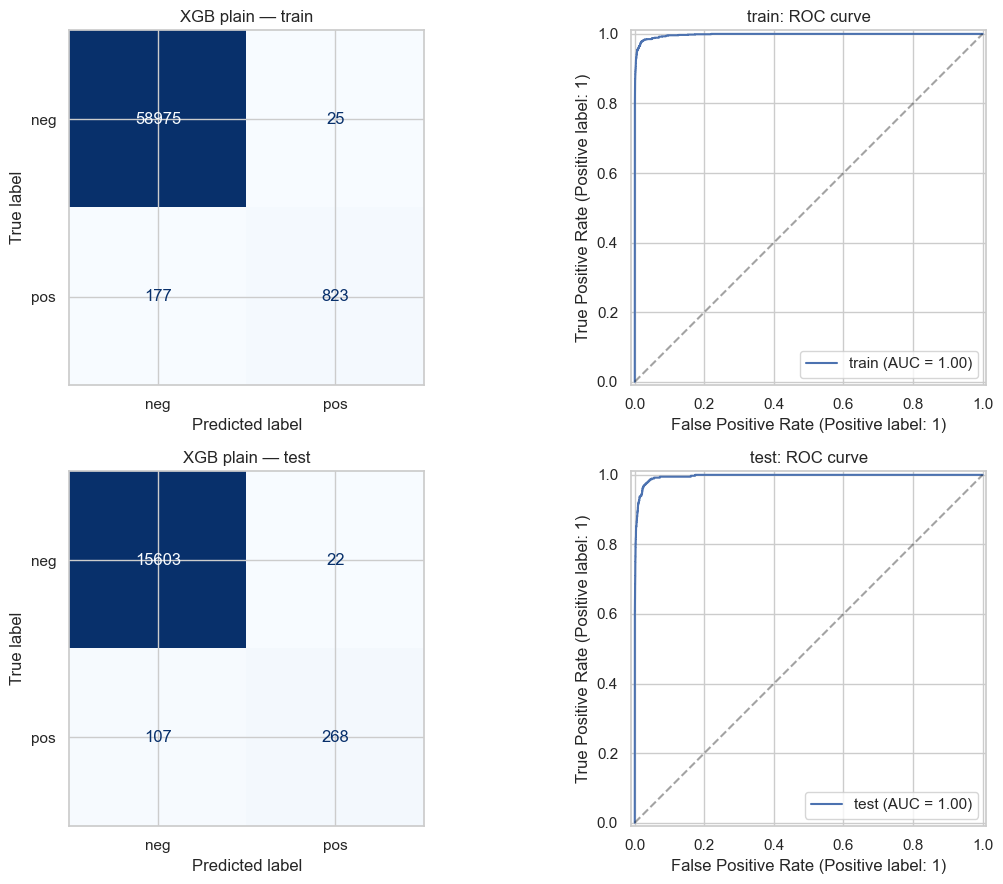

,model,error,ROC_AUC,AP,precision,recall,F1,TN,FP,FN,TP
split,,,,,,,,,,,
train,XGB plain,0.00337,0.99771,0.95374,0.97052,0.82300,0.89069,58975,25,177,823
test,XGB plain,0.00806,0.99620,0.92004,0.92414,0.71467,0.80602,15603,22,107,268


In [14]:
cv_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
alpha_grid = [0.0, 0.1, 1.0, 10.0]

def make_xgb_pipeline(use_smote=False):
    steps = [('imputer', SimpleImputer(strategy='median')),
             ('scaler', StandardScaler())]
    if use_smote:
        steps.append(('smote', SMOTE(sampling_strategy=1.0, k_neighbors=5,
                                     random_state=SEED)))
    steps.append(('xgb', XGBClassifier(
        booster='gbtree', objective='binary:logistic', eval_metric='logloss',
        n_estimators=200, max_depth=3, learning_rate=0.08,
        subsample=1.0, colsample_bytree=1.0,
        reg_lambda=1.0, tree_method='hist', scale_pos_weight=1.0,
        random_state=SEED, n_jobs=N_JOBS)))
    return ImbPipeline(steps)

def tune_xgb(use_smote):
    search = GridSearchCV(
        make_xgb_pipeline(use_smote), {'xgb__reg_alpha': alpha_grid},
        scoring={'accuracy': 'accuracy', 'ROC_AUC': 'roc_auc', 'AP': 'average_precision'},
        refit='accuracy', cv=cv_folds, n_jobs=1, return_train_score=False,
        error_score='raise', verbose=1)
    start = time.perf_counter()
    search.fit(X_train, y_train)
    print(f'Elapsed: {time.perf_counter()-start:.1f} seconds')
    table = pd.DataFrame({
        'alpha': [p['xgb__reg_alpha'] for p in search.cv_results_['params']],
        'CV error': 1-search.cv_results_['mean_test_accuracy'],
        'fold error SD': search.cv_results_['std_test_accuracy'],
        'CV ROC AUC': search.cv_results_['mean_test_ROC_AUC'],
        'CV AP': search.cv_results_['mean_test_AP']
    })
    display(table.round(6))
    print('Selected alpha:', search.best_params_['xgb__reg_alpha'])
    return search, table

xgb_plain_search, cv_plain = tune_xgb(False)
evaluate_model('XGB plain', xgb_plain_search.best_estimator_)

The selected alpha is 0, so the final model has no L1 penalty.

## 1(f). SMOTE and XGBoost

I apply SMOTE to the full training set without downsampling. For the final fit, SMOTE increases the positive class from 1,000 to 59,000 observations, producing 118,000 training observations with equal class counts.

During 5-fold cross-validation, median imputation, standardization, and SMOTE are fitted or applied only to each training fold.
Validation and test sets remain unresampled to prevent data leakage. Standardization is used because SMOTE relies on neighbor distances.

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Elapsed: 37.6 seconds


,alpha,CV error,fold error SD,CV ROC AUC,CV AP
0,0.0,0.016967,0.000889,0.987527,0.810741
1,0.1,0.017183,0.000964,0.987147,0.809389
2,1.0,0.017183,0.000784,0.987337,0.810247
3,10.0,0.017750,0.000905,0.987352,0.808204


Selected alpha: 0.0


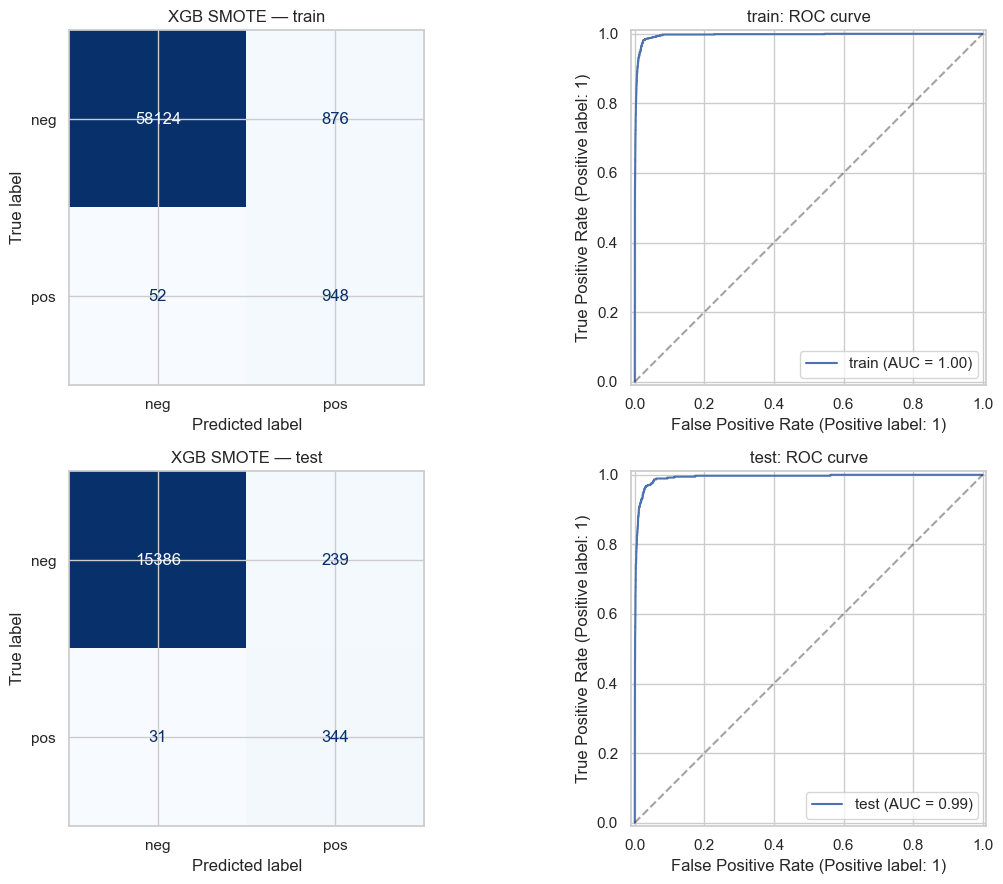

,model,error,ROC_AUC,AP,precision,recall,F1,TN,FP,FN,TP
split,,,,,,,,,,,
train,XGB SMOTE,0.01547,0.99619,0.88399,0.51974,0.94800,0.67139,58124,876,52,948
test,XGB SMOTE,0.01687,0.99333,0.86965,0.59005,0.91733,0.71816,15386,239,31,344


Synthetic rows requested by final SMOTE fit: {np.int64(1): 58000}
Original training rows: 60000
Final training rows after SMOTE: 118000


In [15]:
xgb_smote_search, cv_smote = tune_xgb(True)
evaluate_model('XGB SMOTE', xgb_smote_search.best_estimator_)
# Verify the final sampling target without resampling validation or test observations.
sampler = xgb_smote_search.best_estimator_.named_steps['smote']
print('Synthetic rows requested by final SMOTE fit:', dict(sampler.sampling_strategy_))
print('Original training rows:', len(y_train))
print('Final training rows after SMOTE:', len(y_train) + sum(sampler.sampling_strategy_.values()))

error  ROC_AUC       AP  precision   recall       F1  \
model       split                                                           
RF plain    train  0.00000  1.00000  1.00000    1.00000  1.00000  1.00000   
            test   0.00756  0.99439  0.92428    0.93493  0.72800  0.81859   
RF weighted train  0.00000  1.00000  1.00000    1.00000  1.00000  1.00000   
            test   0.01062  0.99331  0.88284    0.92887  0.59200  0.72313   
XGB plain   train  0.00337  0.99771  0.95374    0.97052  0.82300  0.89069   
            test   0.00806  0.99620  0.92004    0.92414  0.71467  0.80602   
XGB SMOTE   train  0.01547  0.99619  0.88399    0.51974  0.94800  0.67139   
            test   0.01687  0.99333  0.86965    0.59005  0.91733  0.71816   

                      TN   FP   FN    TP  
model       split                         
RF plain    train  59000    0    0  1000  
            test   15606   19  102   273  
RF weighted train  59000    0    0  1000  
            test   15608   17  153   222  
XGB plain   train  58975   25  177   823  
            test   15603   22  107   268  
XGB SMOTE   train  58124  876   52   948  
            test   15386  239   31   344

,alpha,selection CV error,test error,test minus CV
XGB plain,0.0,0.006333,0.008062,0.001729
XGB SMOTE,0.0,0.016967,0.016875,-0.000092


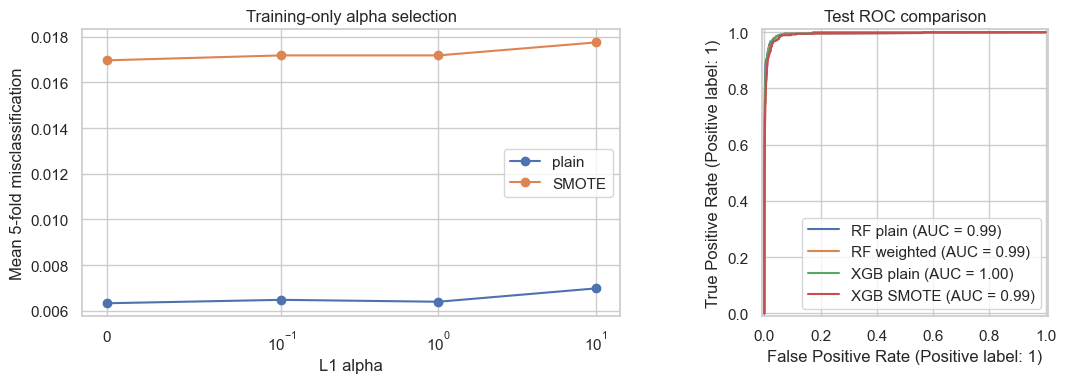

In [16]:
summary = pd.DataFrame(results)
display(summary.set_index(['model', 'split']).round(5))
cv_comparison = pd.DataFrame({
    'alpha': [xgb_plain_search.best_params_['xgb__reg_alpha'], xgb_smote_search.best_params_['xgb__reg_alpha']],
    'selection CV error': [1-xgb_plain_search.best_score_, 1-xgb_smote_search.best_score_],
    'test error': [summary.query("model=='XGB plain' and split=='test'").error.iloc[0],
                   summary.query("model=='XGB SMOTE' and split=='test'").error.iloc[0]]
}, index=['XGB plain', 'XGB SMOTE'])
cv_comparison['test minus CV'] = cv_comparison['test error'] - cv_comparison['selection CV error']
display(cv_comparison.round(6))
summary.to_csv('model_results.csv', index=False)
cv_plain.to_csv('xgb_cv_plain.csv', index=False)
cv_smote.to_csv('xgb_cv_smote.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for table, label in [(cv_plain, 'plain'), (cv_smote, 'SMOTE')]:
    axes[0].plot(table['alpha'], table['CV error'], marker='o', label=label)
axes[0].set_xscale('symlog', linthresh=0.1)
axes[0].set(xlabel='L1 alpha', ylabel='Mean 5-fold misclassification', title='Training-only alpha selection')
axes[0].legend()
for name, model in fitted_models.items():
    RocCurveDisplay.from_predictions(y_test, model.predict_proba(X_test)[:, 1],
                                    name=name, ax=axes[1])
axes[1].set_title('Test ROC comparison')
plt.tight_layout()
plt.show()

In [17]:
xgb_test = summary.query("split == 'test'").set_index('model')

display(
    xgb_test.loc[
        ['XGB plain', 'XGB SMOTE'],
        ['error', 'ROC_AUC', 'FN', 'FP']
    ].style.format({
        'error': '{:.3%}',
        'ROC_AUC': '{:.4f}',
        'FN': '{:.0f}',
        'FP': '{:.0f}'
    })
)

,error,ROC_AUC,FN,FP
model,,,,
XGB plain,0.806%,0.9962,107,22
XGB SMOTE,1.687%,0.9933,31,239


SMOTE increases the test error from 0.806% to 1.687% and decreases ROC AUC from 0.9962 to 0.9933. However, false negatives decrease from 107 to 31, while false positives increase from 22 to 239. Thus, SMOTE detects more positive cases but produces more false alarms. The selected alpha with SMOTE is 0.

## 2. ISLR 6.6.3 — Increasing the lasso constraint

The problem minimizes RSS subject to $\sum_{j=1}^p |\beta_j|\le s$. Increasing $s$ relaxes the constraint, so the model becomes more flexible. At $s=0$, every slope is zero; for a sufficiently large $s$, the least-squares solution is feasible.

| Part | Choice | Explanation |
|---|---|---|
| (a) Training RSS | **iv: decreases** | The feasible set only grows, so the minimum RSS cannot increase. It can stay flat once least squares is reached. |
| (b) Test RSS | **ii: decreases, then increases** | The usual bias–variance pattern: initially flexibility helps, but eventually fitting noise can hurt. This is an expected pattern, not a theorem for every realized dataset. |
| (c) Variance | **iii: increases** | With less shrinkage, the fitted model is generally more sensitive to the sample. |
| (d) Squared bias | **iv: decreases** | Relaxing the constraint generally reduces shrinkage bias. |
| (e) Irreducible error | **v: constant** | Changing a fitting constraint does not change the noise in the data-generating process. |

The exact monotonic guarantee here is for optimal training RSS; the bias/variance descriptions are the textbook's qualitative behavior.

## 3. ISLR 6.6.5 — Identical predictors in ridge and lasso

Let $x_i=x_{i1}=x_{i2}$, $i=1,2$. The variables and response are centered, so $\hat\beta_0=0$. Both fitted values depend only on $t=\beta_1+\beta_2$.

**(a) Ridge objective**, for $\lambda>0$:
$$\min_{\beta_1,\beta_2}\sum_{i=1}^{2}[y_i-x_i(\beta_1+\beta_2)]^2+\lambda(\beta_1^2+\beta_2^2).$$

**(b) Why the ridge coefficients are equal.** For a fixed sum $t$,
$$\beta_1^2+\beta_2^2=\frac{t^2}{2}+\frac{(\beta_1-\beta_2)^2}{2}.$$
The RSS is fixed at that sum, and the penalty is smallest when $\beta_1=\beta_2=t/2$. With $A=\sum x_i^2$ and $B=\sum x_i y_i$, the optimum is $t=B/(A+\lambda/2)$, giving $\hat\beta_1=\hat\beta_2=B/(2A+\lambda)$. Positive $\lambda$ makes the ridge objective strictly convex.

**(c) Lasso objective:**
$$\min_{\beta_1,\beta_2}\sum_{i=1}^{2}[y_i-x_i(\beta_1+\beta_2)]^2+\lambda(|\beta_1|+|\beta_2|).$$

**(d) Why the lasso can have many solutions.** For fixed $t$, the smallest possible penalty is $\lambda|t|$. Every same-sign split of $t$ attains it. Assuming $A>0$,
$$t^*=\frac{\operatorname{sign}(B)(|B|-\lambda/2)_+}{A}.$$
If $t^*>0$, every $(\beta_1,\beta_2)=(u,t^*-u)$ with $0\le u\le t^*$ is optimal. If $t^*<0$, the interval is $t^*\le u\le0$. These different coefficients produce identical predictions. There is an edge case: if $t^*=0$ and $\lambda>0$, only $(0,0)$ minimizes the penalty, so nonuniqueness is not guaranteed for every possible response and penalty. At $\lambda=0$, the identical columns also make ordinary least-squares coefficients nonunique.

In [18]:
# A small check of the algebra; these are invented values, not APS results.
x = np.array([-1., 1.])
y = np.array([-2., 2.])
lam = 1.0
A, B = x @ x, x @ y
t_ridge = B / (A + lam/2)
t_lasso = np.sign(B) * max(abs(B)-lam/2, 0) / A
rows = []
for u in [0, t_lasso/2, t_lasso]:
    beta = np.array([u, t_lasso-u])
    rss = np.sum((y-x*beta.sum())**2)
    rows.append({'beta1': beta[0], 'beta2': beta[1],
                 'lasso objective': rss+lam*np.abs(beta).sum()})
print('Ridge coefficients:', np.repeat(t_ridge/2, 2))
display(pd.DataFrame(rows))

Ridge coefficients: [0.8 0.8]


,beta1,beta2,lasso objective
0,0.000,1.750,1.875
1,0.875,0.875,1.875
2,1.750,0.000,1.875


## 4. ISLR 8.4.5 — Voting versus averaging probabilities

**Majority vote predicts Red.** Six of the ten trees give a red probability greater than 0.5; the other four vote Green.

**Averaging probabilities predicts Green.** The average red probability is 0.45, which is below 0.5. The four fairly confident Green predictions outweigh the six less-confident Red predictions when probabilities are averaged. This shows why hard voting and probability averaging can disagree.

In [19]:
red_probabilities = np.array([0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75])
print('Red votes:', (red_probabilities > 0.5).sum())
print('Green votes:', (red_probabilities <= 0.5).sum())
print('Average red probability:', red_probabilities.mean())

Red votes: 6
Green votes: 4
Average red probability: 0.45


## 5. ISLR 9.7.3 — Maximal margin classifier

**(a)** I plot the seven observations below, labeling them by observation number.

**(b)** The optimal separating hyperplane is
$$X_2-X_1+0.5=0,\qquad \text{or }X_2=X_1-0.5.$$

**(c)** Classify as Red if $0.5-X_1+X_2>0$, and Blue otherwise. One valid coefficient set is $(\beta_0,\beta_1,\beta_2)=(0.5,-1,1)$. Multiplying all three by a positive constant gives the same classifier. To normalize the slope vector to unit norm, use $(0.5,-1,1)/\sqrt2$.

**(d)** The supporting lines are $X_2=X_1$ on the red side and $X_2=X_1-1$ on the blue side. The distance from the decision boundary to either supporting line is
$$M=\frac{0.5}{\sqrt2}=\frac{1}{2\sqrt2}\approx0.3536.$$
The total gap between the supporting lines is $2M=1/\sqrt2$. The closest red and blue convex-hull faces lie on these parallel lines, so a wider separating strip is impossible.

**(e)** Observations **2 and 3 (Red)** and **5 and 6 (Blue)** lie on the margin boundaries and are the geometric support vectors. In a degenerate dual solution, an implementation can report fewer nonzero dual coefficients even though these four points lie on the supporting lines.

**(f)** Observation 7 is strictly outside the margin on the blue side: its distance from the separator is $2.5/\sqrt2$. A sufficiently small movement keeps its constraint inactive, so the maximal-margin boundary is unchanged.

**(g)** A valid but nonoptimal separator is $X_2=X_1-0.2$. Its nearest-point distance is $0.2/\sqrt2$, smaller than $0.5/\sqrt2$.

**(h)** Add a Blue observation at $(2.5,3)$. It is the midpoint of the Red observations 2 and 1, so it lies inside the Red convex hull. No linear hyperplane can then strictly separate all Red and Blue observations. I show this added point in a separate panel, without refitting the original hard-margin boundary.

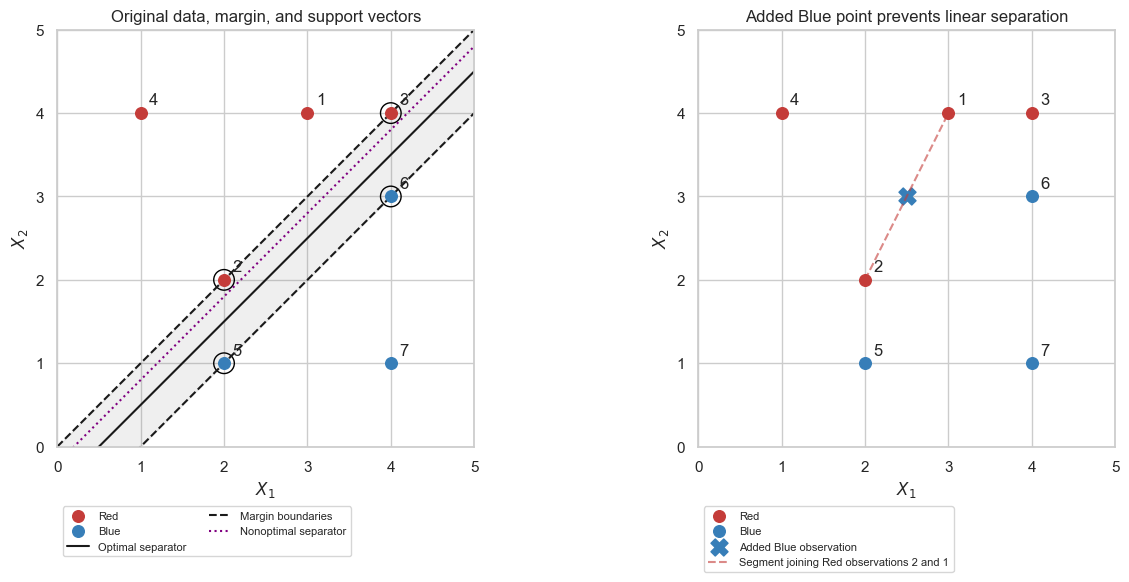

Numerical slope coefficients: [-1.99941  1.99941]
Numerical intercept: [0.99971]
Hand-derived point-to-boundary margin: 0.35355339059327373


In [20]:
toy_X = np.array([[3,4], [2,2], [4,4], [1,4], [2,1], [4,3], [4,1]], dtype=float)
toy_y = np.array([1,1,1,1,-1,-1,-1])
xx = np.linspace(0, 5, 200)
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax in axes:
    for cls, color, label in [(1, '#c43c39', 'Red'), (-1, '#377eb8', 'Blue')]:
        mask = toy_y == cls
        ax.scatter(*toy_X[mask].T, color=color, s=70, label=label, zorder=3)
    for i, (x1, x2) in enumerate(toy_X, 1):
        ax.annotate(str(i), (x1, x2), xytext=(6, 6), textcoords='offset points')
    ax.set(xlim=(0,5), ylim=(0,5), xlabel='$X_1$', ylabel='$X_2$')
    ax.set_aspect('equal')
axes[0].plot(xx, xx-0.5, 'k-', label='Optimal separator')
axes[0].plot(xx, xx, 'k--', label='Margin boundaries')
axes[0].plot(xx, xx-1, 'k--')
axes[0].fill_between(xx, xx-1, xx, color='grey', alpha=0.12)
axes[0].plot(xx, xx-0.2, color='purple', linestyle=':', label='Nonoptimal separator')
axes[0].scatter(*toy_X[[1,2,4,5]].T, s=220, facecolors='none', edgecolors='black')
axes[0].set_title('Original data, margin, and support vectors')
axes[0].legend(loc='upper left', bbox_to_anchor=(0, -0.13), ncol=2, fontsize=8)
axes[1].scatter(2.5, 3, marker='X', color='#377eb8', s=150, label='Added Blue observation')
axes[1].plot([2,3], [2,4], color='#c43c39', linestyle='--', alpha=0.6,
             label='Segment joining Red observations 2 and 1')
axes[1].set_title('Added Blue point prevents linear separation')
axes[1].legend(loc='upper left', bbox_to_anchor=(0, -0.13), ncol=1, fontsize=8)
plt.tight_layout()
plt.show()
# Numerical check of the manually derived optimal separator.
toy_svc = SVC(kernel='linear', C=1e6).fit(toy_X, toy_y)
print('Numerical slope coefficients:', toy_svc.coef_[0].round(5))
print('Numerical intercept:', toy_svc.intercept_.round(5))
print('Hand-derived point-to-boundary margin:', 0.5/np.sqrt(2))